In [5]:
# Week 4: Compare and tune models
# Dataset: Sleep Debt

In [6]:
# Step 1: Load the dataset
import pandas as pd

DATASET_PATH = "/content/bedtime_screentime_sleep_debt.csv"
df = pd.read_csv(DATASET_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0.0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92.0,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45.0,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97.0,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0.0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


In [7]:
# Check missing values and duplicates
print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values:


,0
user_id,0
age,0
gender,0
occupation_type,0
chronotype,0
bedtime_phone_minutes,0
primary_bedtime_app,26
screen_brightness_pct,0
blue_light_filter_active,0
caffeine_post_5pm_mg,21


Duplicate rows: 0


In [8]:
# Clean the data
TARGET = "sleep_debt_category"

df = df.drop_duplicates()
df = df.dropna(subset=[TARGET])

columns_to_exclude = [
    "user_id",
    "total_sleep_hours",
    "sleep_latency_min",
    "deep_sleep_pct",
    "next_day_fatigue_score"
]

columns_to_remove = [col for col in columns_to_exclude if col in df.columns]
df = df.drop(columns=columns_to_remove)

print("Removed columns:", columns_to_remove)
print("Cleaned shape:", df.shape)
print("Target distribution:")
display(df[TARGET].value_counts())

Removed columns: ['user_id', 'total_sleep_hours', 'sleep_latency_min', 'deep_sleep_pct', 'next_day_fatigue_score']
Cleaned shape: (8500, 13)
Target distribution:


,count
sleep_debt_category,
Moderate Debt,4462
Mild Deficit,2004
Optimal Recovery,1387
Severe Sleep Debt,647


In [9]:
# Split features and target
from sklearn.model_selection import train_test_split

X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows (saved for Step 6):", len(X_test))

Training rows: 6800
Testing rows (saved for Step 6): 1700


In [20]:
#step 2:
# Prepare preprocessing and model pipelines
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()


def make_preprocessor():
    numeric = SimpleImputer(strategy="median")
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("num", numeric, numeric_features),
        ("cat", categorical, categorical_features)
    ])

In [11]:
# Set up the four models for comparison
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold


def make_knn_pipeline():
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("scaler", StandardScaler(with_mean=False)),
        ("classifier", KNeighborsClassifier())
    ])


def make_tree_pipeline():
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ])


def make_rf_pipeline():
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", RandomForestClassifier(random_state=42, n_jobs=-1))
    ])


def make_gb_pipeline():
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", GradientBoostingClassifier(random_state=42))
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = "f1_macro"

In [12]:
# Step 2: Compare the four models
from sklearn.model_selection import cross_validate

models = {
    "KNN": make_knn_pipeline(),
    "Decision Tree": make_tree_pipeline(),
    "Random Forest": make_rf_pipeline(),
    "Gradient Boosting": make_gb_pipeline()
}

comparison_rows = []

for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring=SCORING, n_jobs=-1)
    comparison_rows.append({
        "Model": name,
        "Mean CV Macro F1": scores["test_score"].mean(),
        "Std CV Macro F1": scores["test_score"].std()
    })

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.sort_values("Mean CV Macro F1", ascending=False).round(4))

,Model,Mean CV Macro F1,Std CV Macro F1
3,Gradient Boosting,0.7284,0.0049
2,Random Forest,0.7141,0.0048
1,Decision Tree,0.6345,0.0121
0,KNN,0.5593,0.0070


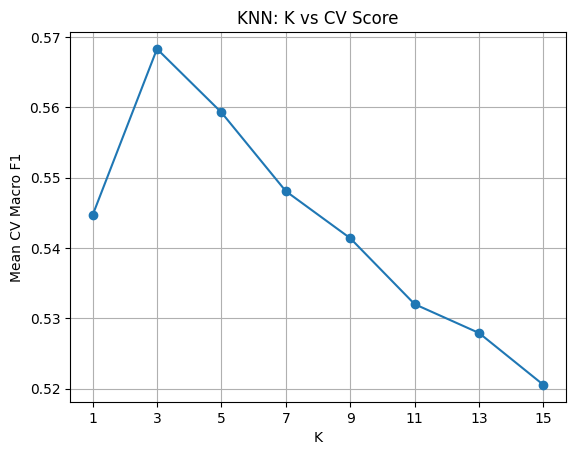

Best K: 3
Best CV Macro F1: 0.5683


In [13]:
# Step 3A: Tune KNN
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt

k_values = list(range(1, 16, 2))

knn_search = GridSearchCV(
    make_knn_pipeline(),
    {"classifier__n_neighbors": k_values},
    scoring=SCORING, cv=cv, n_jobs=-1, return_train_score=True
)
knn_search.fit(X_train, y_train)

plt.plot(k_values, knn_search.cv_results_["mean_test_score"], marker="o")
plt.xlabel("K")
plt.ylabel("Mean CV Macro F1")
plt.title("KNN: K vs CV Score")
plt.xticks(k_values)
plt.grid(True)
plt.show()

best_k = knn_search.best_params_["classifier__n_neighbors"]
print("Best K:", best_k)
print("Best CV Macro F1:", round(knn_search.best_score_, 4))

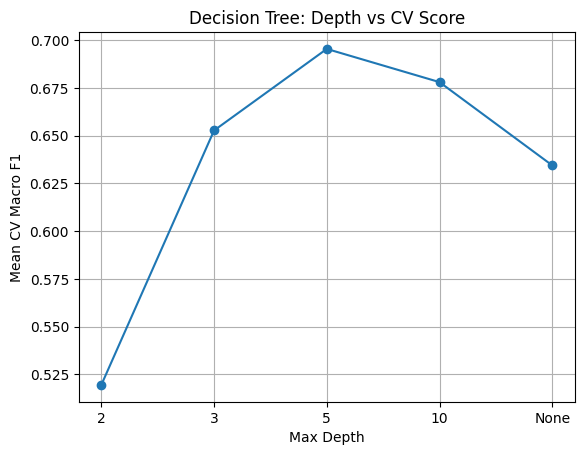

Best max_depth: 5
Best CV Macro F1: 0.6955


In [14]:
# Step 3B: Tune Decision Tree

depth_values = [2, 3, 5, 10, None]

tree_search = GridSearchCV(
    make_tree_pipeline(),
    {"classifier__max_depth": depth_values},
    scoring=SCORING, cv=cv, n_jobs=-1, return_train_score=True
)
tree_search.fit(X_train, y_train)

scores = tree_search.cv_results_["mean_test_score"]
plt.plot([str(x) for x in depth_values], scores, marker="o")
plt.xlabel("Max Depth")
plt.ylabel("Mean CV Macro F1")
plt.title("Decision Tree: Depth vs CV Score")
plt.grid(True)
plt.show()

best_depth = tree_search.best_params_["classifier__max_depth"]
print("Best max_depth:", best_depth)
print("Best CV Macro F1:", round(tree_search.best_score_, 4))

In [15]:
# Step 4A: Tune Random Forest

rf_param_grid = {
    "classifier__n_estimators": [50, 100, 200],
    "classifier__max_depth": [3, 5, None]
}

rf_search = GridSearchCV(
    make_rf_pipeline(), rf_param_grid,
    scoring=SCORING, cv=cv, n_jobs=-1, return_train_score=True
)
rf_search.fit(X_train, y_train)

print("Best parameters:", rf_search.best_params_)
print("Best CV Macro F1:", round(rf_search.best_score_, 4))
print("CV model fits:", 3 * 3 * 5)

Best parameters: {'classifier__max_depth': None, 'classifier__n_estimators': 100}
Best CV Macro F1: 0.7141
CV model fits: 45


In [16]:
# Step 4B: Tune Gradient Boosting

gb_param_grid = {
    "classifier__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "classifier__n_estimators": [50, 100, 200]
}

gb_search = GridSearchCV(
    make_gb_pipeline(), gb_param_grid,
    scoring=SCORING, cv=cv, n_jobs=-1, return_train_score=True
)
gb_search.fit(X_train, y_train)

print("Best parameters:", gb_search.best_params_)
print("Best CV Macro F1:", round(gb_search.best_score_, 4))
print("CV model fits:", 4 * 3 * 5)

ensemble_comparison = pd.DataFrame([
    {"Model": "Random Forest", "Best CV Macro F1": rf_search.best_score_},
    {"Model": "Gradient Boosting", "Best CV Macro F1": gb_search.best_score_}
])
display(ensemble_comparison.sort_values("Best CV Macro F1", ascending=False).round(4))

Best parameters: {'classifier__learning_rate': 0.2, 'classifier__n_estimators': 50}
Best CV Macro F1: 0.7286
CV model fits: 60


,Model,Best CV Macro F1
1,Gradient Boosting,0.7286
0,Random Forest,0.7141


In [17]:
# Step 5: Check overfitting and stability

tuned_models = {
    "KNN": knn_search.best_estimator_,
    "Decision Tree": tree_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_,
    "Gradient Boosting": gb_search.best_estimator_
}

overfit_rows = []

for name, model in tuned_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring=SCORING, return_train_score=True, n_jobs=-1)
    train_score = scores["train_score"].mean()
    val_score = scores["test_score"].mean()
    overfit_rows.append({
        "Model": name,
        "CV Train Score": train_score,
        "CV Validation Score": val_score,
        "Gap": train_score - val_score,
        "Validation Std": scores["test_score"].std()
    })

overfit_table = pd.DataFrame(overfit_rows)
display(overfit_table.sort_values("Gap", ascending=False).round(4))

,Model,CV Train Score,CV Validation Score,Gap,Validation Std
2,Random Forest,1.0000,0.7141,0.2859,0.0048
0,KNN,0.7601,0.5683,0.1918,0.0087
3,Gradient Boosting,0.7980,0.7286,0.0694,0.0046
1,Decision Tree,0.7096,0.6955,0.0142,0.0150


In [ ]:
# Which model overfits the most?

# Random Forest overfits the most because it has a training score of 1.0000
#but a much lower validation score of 0.7141. Its gap is 0.2859.

In [ ]:

# Which model is the most stable?

# Gradient Boosting is the most stable overall. It has the highest validation Macro F1 score (0.7286),
#a relatively small train-validation gap (0.0694), and a low validation standard deviation (0.0046).

# Decision Tree has the smallest train-validation gap, but its validation performance is lower than Gradient Boosting.

Selected model: Gradient Boosting
CV Macro F1: 0.7286
Test Macro F1: 0.7323
Test Accuracy: 0.7629


,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
Mild Deficit,245,96,60,0
Moderate Debt,103,768,1,21
Optimal Recovery,82,3,192,0
Severe Sleep Debt,0,37,0,92


                   precision    recall  f1-score   support

     Mild Deficit       0.57      0.61      0.59       401
    Moderate Debt       0.85      0.86      0.85       893
 Optimal Recovery       0.76      0.69      0.72       277
Severe Sleep Debt       0.81      0.71      0.76       129

         accuracy                           0.76      1700
        macro avg       0.75      0.72      0.73      1700
     weighted avg       0.77      0.76      0.76      1700



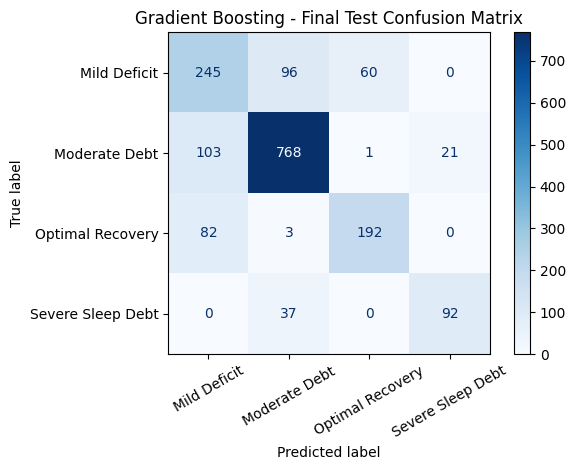

In [24]:
# Step 6: Final test evaluation
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.metrics import f1_score

best_cv_scores = {
    "KNN": knn_search.best_score_,
    "Decision Tree": tree_search.best_score_,
    "Random Forest": rf_search.best_score_,
    "Gradient Boosting": gb_search.best_score_
}

final_model_name = max(best_cv_scores, key=best_cv_scores.get)
final_model = tuned_models[final_model_name]

print("Selected model:", final_model_name)
print("CV Macro F1:", round(best_cv_scores[final_model_name], 4))

final_model.fit(X_train, y_train)
y_test_pred = final_model.predict(X_test)

print("Test Macro F1:", round(
    f1_score(y_test, y_test_pred, average="macro"), 4
))
print("Test Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_test_pred, labels=labels)
display(pd.DataFrame(cm, index=labels, columns=labels))
print(classification_report(y_test, y_test_pred, labels=labels, zero_division=0))

cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
cm_display.plot(cmap="Blues", values_format="d", xticks_rotation=30)
plt.title(final_model_name + " - Final Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Conclusion

In [23]:
# Why was Gradient Boosting selected?

# Gradient Boosting was selected because:
      # ->It achieved the highest cross-validation Macro F1 score (0.7286).
      # ->It performed better than Random Forest (0.7141).
      # ->It had a relatively small train-validation gap.
      # ->Its validation scores were consistent across folds.
      # ->It achieved 76.29% accuracy on the final test set.

In [ ]:

# Which matters more: Precision or Recall?

# For this problem, recall is more important, especially for the Severe Sleep Debt class.Recall
# measures how many actual severe sleep debt cases the model correctly identifies.
# Missing these cases could be more concerning than incorrectly flagging someone as having severe sleep debt.

In [21]:

# The model achieved:

# Severe Sleep Debt Precision: 0.81
# Severe Sleep Debt Recall: 0.71
# This means it correctly identified approximately 71% of actual severe sleep debt cases.
# There is still room to improve recall. Final Decision: Gradient Boosting is the best choice among the tested
# models based on its cross-validation performance, stability, and final test accuracy.